# Week 9: Gradient Boosting, Learning Rate, and Regularization
### Victor Vasquez Gil | Boston University | Integrated Capstone
DX799 — Module C | 9.3 Peer Review: Week 9 Jupyter Notebook

## 1. Research question and connection to my earlier work
My capstone asks whether borrower information available when a loan is issued can help Lending Club analysts identify loans that will later be charged off, without flagging too many borrowers who repay. I have already tested logistic regression, support vector machines, decision trees, and random forests. In Week 6, the matched logistic model reached test ROC-AUC 0.700, compared with 0.688 for the random forest and 0.648 for the tuned tree. That result gave me a reason to be cautious about assuming a more complicated model would work better.

This week, I am testing gradient boosting. Unlike random forest, which combines trees built largely independently, boosting adds trees in sequence to improve the model's errors. The research question I seeking answers to is: Can gradient boosting identify charged-off Lending Club loans better than the logistic regression and random forest models I tested earlier, without creating too many false positives?

The target is unchanged from Weeks 4–6: Charged Off = 1 and Fully Paid = 0. I compare the learning rate, number of estimators, tree depth, minimum leaf size, and subsampling. I use ROC-AUC and average precision to evaluate rankings, and precision, recall, F1, and confusion-matrix counts to examine the consequences of flagging loans for review.

How this notebook is organized: Each section explains the code immediately below it, what its output means, and why it matters to the larger credit-risk project. The analysis selects settings using training-fold cross-validation, chooses cutoffs using validation data, and evaluates the final models using the reserved test split. The final results discussion is generated from the numbers obtained when the notebook runs; it does not assume that boosting has already won.

### 1.1 Libraries and tools
I use pandas and NumPy to prepare the loan data, Matplotlib and Seaborn for figures, and scikit-learn for the models and evaluation. The code below also prints the library versions. I used most of these tools in earlier weeks, so keeping them the same makes the results easier to compare and reproduce. No loans are loaded in this step.

In [15]:
from pathlib import Path
import sys, json, hashlib, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from IPython.display import display, HTML, Markdown
from threadpoolctl import threadpool_limits
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
from sklearn.exceptions import ConvergenceWarning

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

Python 3.14.2 | pandas 3.0.6 | sklearn 1.9.1


## 1.2 Data source and experiment settings
This cell sets the Kaggle dataset reference, random seed, sample sizes, cross-validation folds, and the 15 predictors carried over from Weeks 4–6. It also creates folders to save the figures and tables.

I keep 50,000 resolved loans, with 8,000 training loans used for the matched model comparison. I do not want a different training sample to explain a change in ROC-AUC. The notebook checks for an existing CSV or KaggleHub cache before attempting a download. DATASET_URL identifies the source; it is not a direct CSV link. DATA_PATH can be used to point to an existing file.

In [16]:
SEED = 42
SAMPLE_SIZE = 50_000
CHUNK_SIZE = 25_000
EXPECTED_SOURCE_ROWS = 2_260_701  # Accepted-loans version 3; prevents accidental use of a partial export.
CV_FOLDS = 3
N_JOBS = 1
MODEL_TRAIN_SIZE = 8_000  # Keep the Weeks 5–6 matched comparison exactly the same.
DATA_PATH = None  # Optional: full path to a CSV/CSV.GZ if already downloaded.
DOWNLOAD_IF_MISSING = True  # Reuse local files first; let KaggleHub fetch version 3 if needed.
DATASET_URL = "https://www.kaggle.com/datasets/wordsforthewise/lending-club"
DATASET_VERSION = 3
OUTPUT_DIR = Path("week9_outputs")
CACHE_DIR = Path("capstone_cache")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR.mkdir(parents=True, exist_ok=True)
thread_limit = threadpool_limits(limits=1)
NUMERIC = ["loan_amnt", "annual_inc", "dti", "fico_range_low", "open_acc",
           "pub_rec", "revol_bal", "revol_util", "total_acc", "delinq_2yrs", "inq_last_6mths"]
CATEGORICAL = ["term", "home_ownership", "purpose", "emp_length"]
FEATURES = NUMERIC + CATEGORICAL
BLUE, TEAL, ORANGE, GRAY, PURPLE = "#315F91", "#137C8B", "#B85C20", "#6B7280", "#8064A2"
sns.set_theme(style="whitegrid", rc={"figure.dpi":120,"font.family":"DejaVu Sans",
    "axes.spines.top":False,"axes.spines.right":False,"grid.alpha":0.25})

## 1.3 Functions used throughout the notebook
The next cell defines how I find and read the accepted-loans file, sample eligible rows, prepare the target and predictors, and calculate the evaluation metrics. It also defines the plotting functions used later.

I keep the cleaning steps in shared functions so gradient boosting, logistic regression, and random forest are evaluated consistently. Missing values and categorical features are processed inside each training fold, rather than using information from validation or test data. These functions are defined here; the actual analysis starts in the next section.

In [17]:
def show_table(frame, decimals=3):
    formatters = {c: (lambda x: f"{x:,.{decimals}f}") for c in frame.select_dtypes(include="floating").columns}
    display(HTML('<style>.cap-table{border-collapse:collapse;font-family:system-ui;font-size:13px;}'
        '.cap-table th{background:#172B4D;color:white;padding:8px;}'
        '.cap-table td{padding:8px;border-bottom:1px solid #ddd;}'
        '.cap-table tr:nth-child(even){background:#f3f6f8;}</style>' +
        frame.to_html(index=False, border=0, classes="cap-table", formatters=formatters)))

def finish(fig, name):
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=180, bbox_inches="tight", facecolor="white")
    plt.show()

def clean_number(s):
    return pd.to_numeric(s.astype("string").str.strip().str.replace(",", "", regex=False)
        .str.replace("%", "", regex=False), errors="coerce").astype(float).replace([np.inf, -np.inf], np.nan)

def _accepted_file(folder):
    """Select one accepted-loans CSV from a directory, preferring the compressed file."""
    folder = Path(folder)
    if folder.is_file() and folder.name in (
        "accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv"):
        return folder
    if not folder.is_dir():
        return None
    names = ("accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv")
    for name in names:
        direct = folder / name
        if direct.is_file():
            return direct
    # Dataset files can be nested inside the Kaggle input mount or download directory.
    for name in names:
        files = sorted(p for p in folder.rglob(name) if p.is_file())
        if files:
            return files[0]
    return None


def locate_source(configured):
    """Look for local Lending Club CSV, then retrieve the pinned Kaggle version if enabled."""
    if configured is not None:
        path = Path(configured).expanduser()
        if path.is_file():
            print(f"Using DATA_PATH: {path}")
            return path
        raise FileNotFoundError(
            f"DATA_PATH was set but does not exist: {path}. "
            "Set DATA_PATH to the accepted-loans CSV or leave it as None."
        )

    # Reuse the precise version used in earlier weeks wherever it is already present.
    roots = [
        Path.home()/".cache/kagglehub/datasets/wordsforthewise/lending-club/versions"/str(DATASET_VERSION),
        Path("/kaggle/input"),      # Kaggle notebook
        Path("/content"),           # Google Colab
        Path.cwd()/"data",
        Path.cwd(),
        Path.home()/"Downloads",
    ]
    for root in roots:
        found = _accepted_file(root)
        if found:
            print(f"Using existing dataset: {found}")
            return found

    if not DOWNLOAD_IF_MISSING:
        raise FileNotFoundError(
            "The Lending Club accepted-loans CSV was not found locally. "
            "Set DATA_PATH to the file, or set DOWNLOAD_IF_MISSING = True."
        )

    # DATASET_URL is the original Kaggle landing page, not a CSV endpoint.
    # KaggleHub accepts its owner/dataset handle and a pinned version number.
    from urllib.parse import urlparse
    parsed = urlparse(DATASET_URL)
    pieces = [piece for piece in parsed.path.split("/") if piece]
    if parsed.netloc not in ("www.kaggle.com", "kaggle.com") or len(pieces) < 3 or pieces[0] != "datasets":
        raise ValueError(f"Expected a Kaggle dataset webpage URL, got: {DATASET_URL}")
    handle = f"{pieces[1]}/{pieces[2]}/versions/{DATASET_VERSION}"
    try:
        import kagglehub
    except ImportError as exc:
        raise ImportError(
            "KaggleHub is required because there is no local dataset file. "
            "Run `%pip install kagglehub` in a notebook cell, then restart and Run All. "
            "Alternatively, set DATA_PATH to the existing accepted-loans CSV/CSV.GZ."
        ) from exc

    print(f"No existing CSV found. Downloading Kaggle dataset {handle} (once; cached afterward).")
    errors = []
    for filename in ("accepted_2007_to_2018Q4.csv.gz", "accepted_2007_to_2018Q4.csv"):
        try:
            retrieved = Path(kagglehub.dataset_download(handle, path=filename))
            found = _accepted_file(retrieved)
            if found:
                print(f"Dataset file ready: {found}")
                return found
        except Exception as exc:
            errors.append(f"{filename}: {type(exc).__name__}: {exc}")
    raise FileNotFoundError(
        "Could not retrieve the Lending Club accepted-loans file using KaggleHub. "
        "Check network access and Kaggle login/permissions, or set DATA_PATH manually. "
        "Details: " + " | ".join(errors)
    )

def sample_loans(path, cohort):
    fingerprint = {"resolved_path":str(path.resolve()),"bytes":path.stat().st_size,
        "mtime_ns":path.stat().st_mtime_ns,"cohort":cohort,"seed":SEED,
        "sample_size":SAMPLE_SIZE,"chunk_size":CHUNK_SIZE,"algorithm":"priority-v1"}
    key = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()[:16]
    cache_file = CACHE_DIR/f"{cohort}_{key}.csv.gz"
    info_file = CACHE_DIR/f"{cohort}_{key}.json"
    if cache_file.is_file() and info_file.is_file():
        info = json.loads(info_file.read_text())
        sample = pd.read_csv(cache_file, dtype="string")
        sample["source_row"] = pd.to_numeric(sample["source_row"]).astype("int64")
        if info["rows_scanned"] != EXPECTED_SOURCE_ROWS:
            raise ValueError("Cached source row count does not match the expected version-3 file.")
        if len(sample) != min(SAMPLE_SIZE, info["eligible_rows"]):
            raise ValueError("Incomplete sample cache: remove these two cache files and rerun.")
        print("Reusing the local sample cache.")
        return sample, info
    header = pd.read_csv(path, nrows=0)
    required = FEATURES + (["int_rate"] if cohort=="pricing" else ["loan_status"])
    absent = sorted(set(required)-set(header.columns))
    if absent: raise ValueError(f"Required columns missing: {absent}")
    requested = list(dict.fromkeys(FEATURES+["int_rate","loan_status","id","member_id","issue_d"]))
    requested = [c for c in requested if c in header.columns]
    rng = np.random.default_rng(SEED)
    sample = None
    scanned = eligible = 0
    for batch, chunk in enumerate(pd.read_csv(path, usecols=requested, dtype="string",
                                             chunksize=CHUNK_SIZE, low_memory=False),1):
        chunk["source_row"] = np.arange(scanned, scanned+len(chunk))
        scanned += len(chunk)
        if cohort=="pricing":
            rate = clean_number(chunk["int_rate"])
            chunk = chunk.loc[rate.gt(0) & rate.lt(100)].copy()
        else:
            chunk["loan_status"] = chunk["loan_status"].str.strip()
            chunk = chunk.loc[chunk["loan_status"].isin(["Fully Paid","Charged Off"])].copy()
        eligible += len(chunk)
        if len(chunk):
            chunk["_priority"] = rng.random(len(chunk))
            sample = chunk if sample is None else pd.concat([sample,chunk],ignore_index=True)
            sample = sample.nsmallest(SAMPLE_SIZE,"_priority")
        if batch%20==0: print(f"Scanned {scanned:,} source rows...")
    if scanned != EXPECTED_SOURCE_ROWS:
        raise ValueError(f"Scanned {scanned:,} rows; expected {EXPECTED_SOURCE_ROWS:,} for version 3. Check for a partial/different file before continuing.")
    if sample is None or len(sample)<100: raise ValueError("Too few eligible rows.")
    sample = sample.drop(columns="_priority").reset_index(drop=True)
    info = {**fingerprint,"rows_scanned":scanned,"eligible_rows":eligible,"sample_rows":len(sample)}
    sample.to_csv(cache_file,index=False,compression="gzip")
    info_file.write_text(json.dumps(info,indent=2))
    return sample,info

def prepare_xy(loans, cohort):
    for key in ["id","member_id"]:
        if key not in loans: continue
        ids = loans[key].astype("string").str.strip().replace("",pd.NA).dropna()
        if len(ids) and ids.duplicated().any():
            raise ValueError(f"Repeated {key}: resolve duplicate loans or use borrower-group splits before running the analysis.")
    if "member_id" not in loans or loans["member_id"].isna().all():
        print("No usable borrower ID: repeated-borrower dependence remains a limitation.")
    X = loans[FEATURES].copy()
    for col in NUMERIC: X[col] = clean_number(X[col])
    for col in CATEGORICAL:
        values = X[col].astype("string").str.strip().replace("",pd.NA)
        X[col] = values.astype(object).where(values.notna(),np.nan)
    y = (clean_number(loans["int_rate"]).rename("interest_rate") if cohort=="pricing" else
         loans["loan_status"].str.strip().map({"Fully Paid":0,"Charged Off":1}).astype(int).rename("charged_off"))
    assert X.index.equals(y.index) and y.notna().all()
    return X,y

def make_preprocessor(columns=None, numeric_scale=True, scale_all=False):
    columns = FEATURES if columns is None else list(columns)
    transforms=[]
    for i,col in enumerate(columns):
        if col in NUMERIC:
            steps=[("impute",SimpleImputer(strategy="median",keep_empty_features=True))]
            if numeric_scale: steps.append(("scale",StandardScaler()))
        else:
            steps=[("impute",SimpleImputer(strategy="constant",fill_value="Missing",keep_empty_features=True)),
                   ("encode",OneHotEncoder(drop="first",handle_unknown="ignore",sparse_output=False))]
        transforms.append((f"g{i:02d}",Pipeline(steps),[col]))
    prepare=ColumnTransformer(transforms,remainder="drop",verbose_feature_names_out=True)
    return Pipeline([("columns",prepare),("scale",StandardScaler())]) if scale_all else prepare

def choose_threshold(target,scores,default):
    grid=np.unique(np.r_[default,np.quantile(scores,np.linspace(0.01,0.99,99))])
    table=pd.DataFrame([{"Threshold":float(t),"Precision":precision_score(target,scores>=t,zero_division=0),
        "Recall":recall_score(target,scores>=t,zero_division=0),"F1":f1_score(target,scores>=t,zero_division=0)} for t in grid])
    chosen=float(table.sort_values(["F1","Threshold"],ascending=[False,False]).iloc[0]["Threshold"])
    return chosen,table

def classification_metrics(name,target,scores,threshold,rule):
    pred=np.asarray(scores)>=threshold
    tn,fp,fn,tp=confusion_matrix(target,pred,labels=[0,1]).ravel()
    return {"Model":name,"Rule":rule,"Threshold":float(threshold),"Accuracy":accuracy_score(target,pred),
        "Balanced accuracy":balanced_accuracy_score(target,pred),"Precision":precision_score(target,pred,zero_division=0),
        "Recall":recall_score(target,pred,zero_division=0),"F1":f1_score(target,pred,zero_division=0),
        "ROC-AUC":roc_auc_score(target,scores),"Average precision":average_precision_score(target,scores),
        "Flagged share":float(pred.mean()),"TP":int(tp),"FP":int(fp),"FN":int(fn),"TN":int(tn)}

def plot_ranking(target,score_dict,filename):
    fig,axes=plt.subplots(1,2,figsize=(12,4.5),layout="constrained")
    for (name,scores),color in zip(score_dict.items(),[TEAL,BLUE,ORANGE,PURPLE,GRAY]):
        fpr,tpr,_=roc_curve(target,scores)
        precision,recall,_=precision_recall_curve(target,scores)
        axes[0].plot(fpr,tpr,color=color,label=f"{name} ({roc_auc_score(target,scores):.3f})")
        axes[1].step(recall,precision,where="post",color=color,label=f"{name} ({average_precision_score(target,scores):.3f})")
    axes[0].plot([0,1],[0,1],ls="--",color=GRAY)
    axes[1].axhline(float(np.mean(target)),ls="--",color=GRAY,label=f"Prevalence ({np.mean(target):.3f})")
    axes[0].set(title="Test ROC curves (legend = AUC)",xlabel="False positive rate",ylabel="Recall",xlim=(0,1),ylim=(0,1.02))
    axes[1].set(title="Test precision-recall curves (legend = AP)",xlabel="Recall",ylabel="Precision",xlim=(0,1),ylim=(0,1.02))
    for ax in axes: ax.legend(fontsize=8)
    finish(fig,filename)

def plot_confusions(target,scores,default,chosen,name,filename):
    fig,axes=plt.subplots(1,2,figsize=(11,4.4),layout="constrained")
    for ax,t,label in [(axes[0],default,"Default"),(axes[1],chosen,"Validation-selected")]:
        ConfusionMatrixDisplay.from_predictions(target,scores>=t,labels=[0,1],display_labels=["Fully paid","Charged off"],
            values_format=",d",cmap="Blues",colorbar=False,ax=ax)
        ax.set_title(f"{label}: {t:.3f}");ax.grid(False)
    fig.suptitle(f"{name}: the cost of changing the threshold",fontweight="bold")
    finish(fig,filename)

## 2. Use the same loans and splits as the earlier models
The code locates the accepted-loans dataset, samples 50,000 loans labeled Fully Paid or Charged Off, and prepares the same 11 numeric and four categorical predictors used in my earlier classification notebooks. It creates a 30,000-loan training pool, 10,000-loan validation set, and 10,000-loan test set. As in Weeks 5–6, I fit the models on the same stratified 8,000-loan subset of that training pool.

I exclude payments, recoveries, later FICO information, and the lender's existing price or risk indicators, including interest rate, grade, subgrade, and installment. Using those variables could make a model appear more useful than it would be when reviewing a new loan.

I expect the output to confirm the split sizes and the roughly 20% charged-off share I saw earlier. If either changes, I need to check the source file and sampling before comparing scores. The source URL below is a citation, not a CSV address:

Lending Club accepted loans — Kaggle (version 3).

The loader first checks for an existing file. If it cannot find one and DOWNLOAD_IF_MISSING = True, it uses KaggleHub; if the package is missing, it needs to be installed in the notebook environment. A random split helps with comparison across weeks, but it does not tell me how well the models would perform on loans issued later. The dataset also contains only accepted loans with resolved outcomes.

In [18]:
print(f"Dataset reference: {DATASET_URL}")
print("Checking for an existing accepted-loans CSV; KaggleHub fallback enabled:", DOWNLOAD_IF_MISSING)
DATA_PATH = locate_source(DATA_PATH)
print("Reading:", DATA_PATH)
loans,source_info=sample_loans(DATA_PATH,"outcome")
X,y=prepare_xy(loans,"outcome")
X_dev,X_test,y_dev,y_test=train_test_split(X,y,test_size=0.20,stratify=y,random_state=SEED)
X_train,X_val,y_train,y_val=train_test_split(X_dev,y_dev,test_size=0.25,stratify=y_dev,random_state=SEED)
if len(X_train)>MODEL_TRAIN_SIZE:
    fit_indices,_=train_test_split(X_train.index,train_size=MODEL_TRAIN_SIZE,stratify=y_train,random_state=SEED)
    X_fit,y_fit=X_train.loc[fit_indices],y_train.loc[fit_indices]
else:
    X_fit,y_fit=X_train.copy(),y_train.copy()
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert y_fit.value_counts().min()>=CV_FOLDS
cv_splits=list(StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED).split(X_fit,y_fit))
manifest=loans[["source_row"]].copy();manifest["split"]="training pool not used"
manifest.loc[X_fit.index,"split"]="model training / CV"
manifest.loc[X_val.index,"split"]="validation / thresholds"
manifest.loc[X_test.index,"split"]="test"
manifest.to_csv(OUTPUT_DIR/"split_manifest.csv",index=False)
split_table=pd.DataFrame([{"Split":name,"Loans":len(target),"Charged-off share":float(target.mean())}
    for name,target in [("Training pool",y_train),("Model training (subset of pool)",y_fit),
                        ("Validation",y_val),("Test",y_test)]])
show_table(split_table)
print(f"{len(X_train)-len(X_fit):,} training-pool loans are unused; they are not added to validation or test.")

Dataset reference: https://www.kaggle.com/datasets/wordsforthewise/lending-club
Checking for an existing accepted-loans CSV; KaggleHub fallback enabled: True
Using existing dataset: /home/codespace/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/accepted_2007_to_2018Q4.csv.gz
Reading: /home/codespace/.cache/kagglehub/datasets/wordsforthewise/lending-club/versions/3/accepted_2007_to_2018Q4.csv.gz
Reusing the local sample cache.
No usable borrower ID: repeated-borrower dependence remains a limitation.


Split,Loans,Charged-off share
Training pool,30000,0.199
Model training (subset of pool),8000,0.199
Validation,10000,0.199
Test,10000,0.199


22,000 training-pool loans are unused; they are not added to validation or test.


## 3. What the training data tells me
Before fitting a model, I check the share of charged-off loans, missing values, and the FICO distributions for both outcomes. The code produces Figure 1 using the training subset only.

About one in five loans in my earlier sample charged off. Predicting Fully Paid for everyone would therefore look roughly 80% accurate while missing every charge-off. That is why accuracy alone would be misleading for my project. I focus on ROC-AUC and average precision for ranking, followed by recall and precision when deciding which loans to flag.

In Figure 1, overlapping FICO distributions would mean that credit score alone does not separate the outcomes cleanly. The missing-value panel shows why imputation needs to be part of the training pipeline. This EDA helps explain the modeling choices, but it does not establish that any of these features causes a charge-off.

Feature,Missing (%)
emp_length,5.80
revol_util,0.05
loan_amnt,0.00
fico_range_low,0.00
open_acc,0.00
annual_inc,0.00
dti,0.00
revol_bal,0.00


Model training charged-off share: 19.9%
Test data will not be used for EDA or tuning.


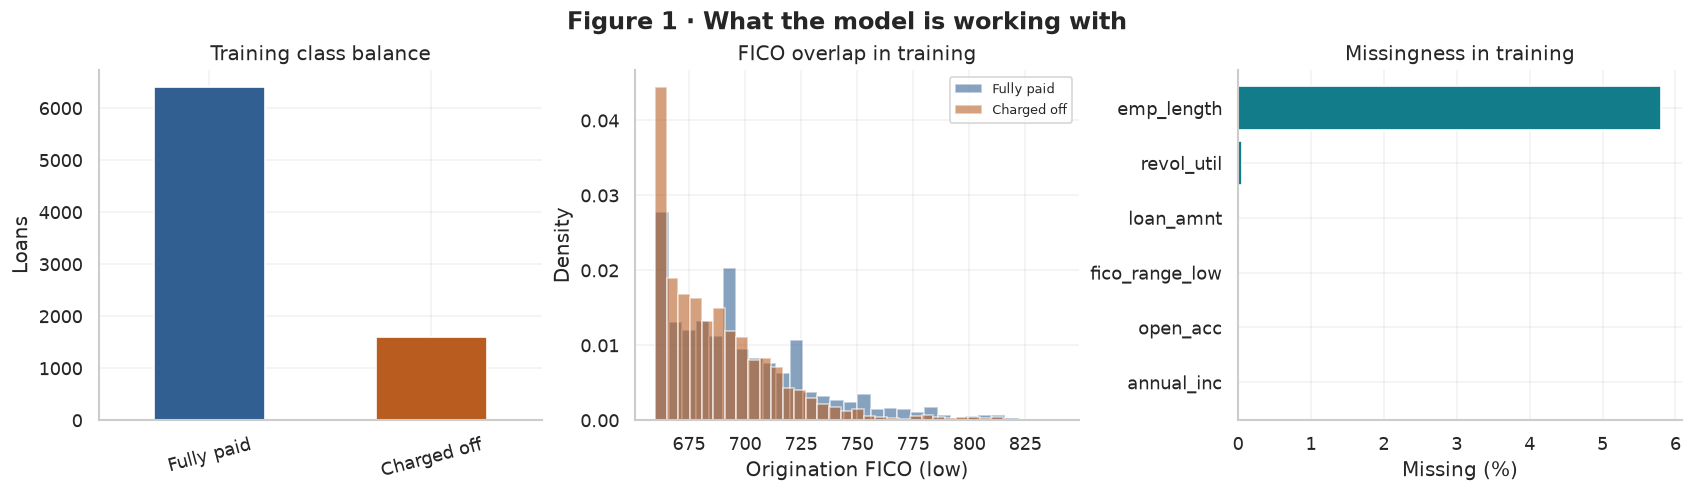

In [19]:
missing = (X_fit.isna().mean().mul(100).rename("Missing (%)")
           .rename_axis("Feature").reset_index().sort_values("Missing (%)", ascending=False))
show_table(missing.head(8), 2)
print("Model training charged-off share:", f"{y_fit.mean():.1%}")
print("Test data will not be used for EDA or tuning.")

plot_frame = X_fit[["fico_range_low", "dti"]].copy()
plot_frame["Outcome"] = y_fit.map({0: "Fully paid", 1: "Charged off"})
fig, axes = plt.subplots(1, 3, figsize=(14, 4), layout="constrained")
y_fit.map({0:"Fully paid", 1:"Charged off"}).value_counts().reindex(["Fully paid", "Charged off"]).plot.bar(
    ax=axes[0], color=[BLUE, ORANGE])
axes[0].set(title="Training class balance", xlabel="", ylabel="Loans")
axes[0].tick_params(axis="x", rotation=15)
for label, color in [("Fully paid", BLUE), ("Charged off", ORANGE)]:
    s = plot_frame.loc[plot_frame.Outcome.eq(label), "fico_range_low"].dropna()
    axes[1].hist(s, bins=30, alpha=.58, density=True, color=color, label=label)
axes[1].set(title="FICO overlap in training", xlabel="Origination FICO (low)", ylabel="Density")
axes[1].legend(fontsize=8)
axes[2].barh(missing.head(6).iloc[::-1]["Feature"], missing.head(6).iloc[::-1]["Missing (%)"], color=TEAL)
axes[2].set(title="Missingness in training", xlabel="Missing (%)")
fig.suptitle("Figure 1 · What the model is working with", fontweight="bold")
finish(fig, "figure_1_training_eda")

## 4. How gradient boosting applies to credit risk
In Week 6, random forest combined many trees that were built largely independently. Gradient boosting works differently: it adds trees sequentially, each one improving the current model's predictions. For classification, scikit-learn's GradientBoostingClassifier fits stages to reduce log loss, rather than simply fitting raw 0/1 errors.

The settings I want to compare affect different parts of that process:
- Learning rate: controls the size of each tree's contribution. Smaller steps often need more trees; a smaller rate is not automatically better.
- Number of estimators: controls how many boosting stages are fitted. Too few may miss patterns, while too many may overfit.
- Maximum depth: limits the complexity of individual trees. Deeper trees can capture interactions but may fit noise.
- Minimum leaf size: keeps individual leaves from being based on very small groups of loans.
- Subsample: lets each stage use only part of the training rows. This can reduce overfitting, although it may also reduce fit.
I will select the model by cross-validation ROC-AUC and also report average precision, which is useful when charge-offs are the minority outcome. Later, I will check whether any ranking improvement is worth the extra false positives.

Technical source: https://scikit-learn.org/stable/modules/ensemble.html 

## 5. Select the boosting settings using cross-validation
This cell fits ten prespecified configurations using three-fold stratified cross-validation on the same 8,000 training loans. The reference has 200 trees, learning rate 0.05, depth 2, minimum leaf size 20, and subsample 0.80. Each alternative changes one setting at a time. The code reports mean training ROC-AUC, mean CV ROC-AUC, average precision, fold variation, and fitting time.

I use the highest mean CV ROC-AUC to select the model, then refit it on the 8,000 loans. The test data are not used to choose settings. When reading the table, I look at both the CV score and the training–CV gap. If one configuration looks much better in training but not across held-out folds, that is a warning sign of overfitting.

This search is deliberately limited. In particular, learning rate and tree count interact, so these one-setting comparisons do not establish the best possible combination.

In [20]:
def classifier_pipeline(estimator, scale_numeric=False):
    return Pipeline([("prepare", make_preprocessor(numeric_scale=scale_numeric)),
                     ("model", estimator)])

# Each row changes only one setting relative to the reference configuration.
reference = dict(learning_rate=.05, n_estimators=200, max_depth=2,
                 min_samples_leaf=20, subsample=.8)
experiments = [
    ("Reference", reference),
    ("Smaller learning rate", {**reference, "learning_rate":.02}),
    ("Larger learning rate", {**reference, "learning_rate":.10}),
    ("Fewer trees", {**reference, "n_estimators":100}),
    ("More trees", {**reference, "n_estimators":400}),
    ("Shallower trees", {**reference, "max_depth":1}),
    ("Deeper trees", {**reference, "max_depth":3}),
    ("Smaller leaves", {**reference, "min_samples_leaf":5}),
    ("Larger leaves", {**reference, "min_samples_leaf":50}),
    ("No row subsampling", {**reference, "subsample":1.0}),
]
settings = pd.DataFrame([{"Experiment":name, **params} for name,params in experiments])
show_table(settings, 3)

param_grid = [{f"model__{key}":[value] for key,value in params.items()}
              for _,params in experiments]
boost_pipeline = classifier_pipeline(GradientBoostingClassifier(loss="log_loss", random_state=SEED))
print("Cross-validating 10 prespecified boosting configurations...")
start = time.perf_counter()
boost_search = GridSearchCV(
    boost_pipeline, param_grid=param_grid,
    scoring={"auc":"roc_auc", "ap":"average_precision"},
    refit="auc", cv=cv_splits, n_jobs=N_JOBS,
    return_train_score=True, error_score="raise", verbose=0
).fit(X_fit, y_fit)
print(f"Finished boosting CV and refit in {(time.perf_counter()-start)/60:.1f} minutes")

raw_cv = pd.DataFrame(boost_search.cv_results_)
cv_table = settings.copy()
cv_table["CV ROC-AUC"] = raw_cv["mean_test_auc"].to_numpy()
cv_table["CV AP"] = raw_cv["mean_test_ap"].to_numpy()
cv_table["Train ROC-AUC"] = raw_cv["mean_train_auc"].to_numpy()
cv_table["Train - CV gap"] = cv_table["Train ROC-AUC"] - cv_table["CV ROC-AUC"]
cv_table["CV fold SD"] = [np.std([raw_cv.loc[i, f"split{k}_test_auc"]
                     for k in range(CV_FOLDS)], ddof=1) for i in raw_cv.index]
cv_table["Mean fit sec"] = raw_cv["mean_fit_time"].to_numpy()
cv_table["Rank"] = raw_cv["rank_test_auc"].to_numpy()
cv_table.sort_values(["Rank","Experiment"]).to_csv(OUTPUT_DIR / "boosting_cv_search.csv", index=False)
show_table(cv_table.sort_values(["Rank","Experiment"]), 4)
selected_boost = boost_search.best_estimator_
chosen_settings = boost_search.best_params_
print("CV-selected boosting settings:", chosen_settings)
print(f"Best mean CV ROC-AUC: {boost_search.best_score_:.4f}")

Experiment,learning_rate,n_estimators,max_depth,min_samples_leaf,subsample
Reference,0.050,200,2,20,0.800
Smaller learning rate,0.020,200,2,20,0.800
Larger learning rate,0.100,200,2,20,0.800
Fewer trees,0.050,100,2,20,0.800
More trees,0.050,400,2,20,0.800
Shallower trees,0.050,200,1,20,0.800
Deeper trees,0.050,200,3,20,0.800
Smaller leaves,0.050,200,2,5,0.800
Larger leaves,0.050,200,2,50,0.800
No row subsampling,0.050,200,2,20,1.000


Cross-validating 10 prespecified boosting configurations...


/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, U

Finished boosting CV and refit in 0.9 minutes


Experiment,learning_rate,n_estimators,max_depth,min_samples_leaf,subsample,CV ROC-AUC,CV AP,Train ROC-AUC,Train - CV gap,CV fold SD,Mean fit sec,Rank
Larger leaves,0.0500,200,2,50,0.8000,0.6870,0.3588,0.7464,0.0594,0.0120,1.4687,1
Reference,0.0500,200,2,20,0.8000,0.6861,0.3575,0.7509,0.0648,0.0125,1.5921,2
Smaller leaves,0.0500,200,2,5,0.8000,0.6844,0.3531,0.7540,0.0696,0.0120,1.4670,3
No row subsampling,0.0500,200,2,20,1.0000,0.6842,0.3531,0.7490,0.0649,0.0117,2.5933,4
Smaller learning rate,0.0200,200,2,20,0.8000,0.6833,0.3512,0.7215,0.0382,0.0100,1.6339,5
Fewer trees,0.0500,100,2,20,0.8000,0.6832,0.3509,0.7274,0.0441,0.0102,0.8007,6
More trees,0.0500,400,2,20,0.8000,0.6829,0.3553,0.7794,0.0965,0.0131,2.8461,7
Larger learning rate,0.1000,200,2,20,0.8000,0.6820,0.3552,0.7757,0.0937,0.0144,1.4475,8
Deeper trees,0.0500,200,3,20,0.8000,0.6800,0.3519,0.8010,0.1210,0.0118,2.1104,9
Shallower trees,0.0500,200,1,20,0.8000,0.6798,0.3477,0.7055,0.0258,0.0126,0.9170,10


CV-selected boosting settings: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 50, 'model__n_estimators': 200, 'model__subsample': 0.8}
Best mean CV ROC-AUC: 0.6870


## 6. Figures 2 and 3: what changed when I tuned the model?
Figure 2 compares the learning rate, number of trees, and depth experiments using their mean CV ROC-AUC. The error bars show variation across the three folds, and the dashed line marks the reference setting. Figure 3 shows the gap between training and CV ROC-AUC for all ten configurations.

I am looking for settings that perform better on held-out folds, not only on the training loans. In Week 6, the unrestricted tree reached a training ROC-AUC of 1.000 but only 0.549 in CV. That result showed how misleading a high training score can be.

These figures also need to be read carefully. A difference of a few thousandths may be smaller than the fold variation. And comparing learning rates at a fixed number of trees does not show how a smaller learning rate would perform with more stages.

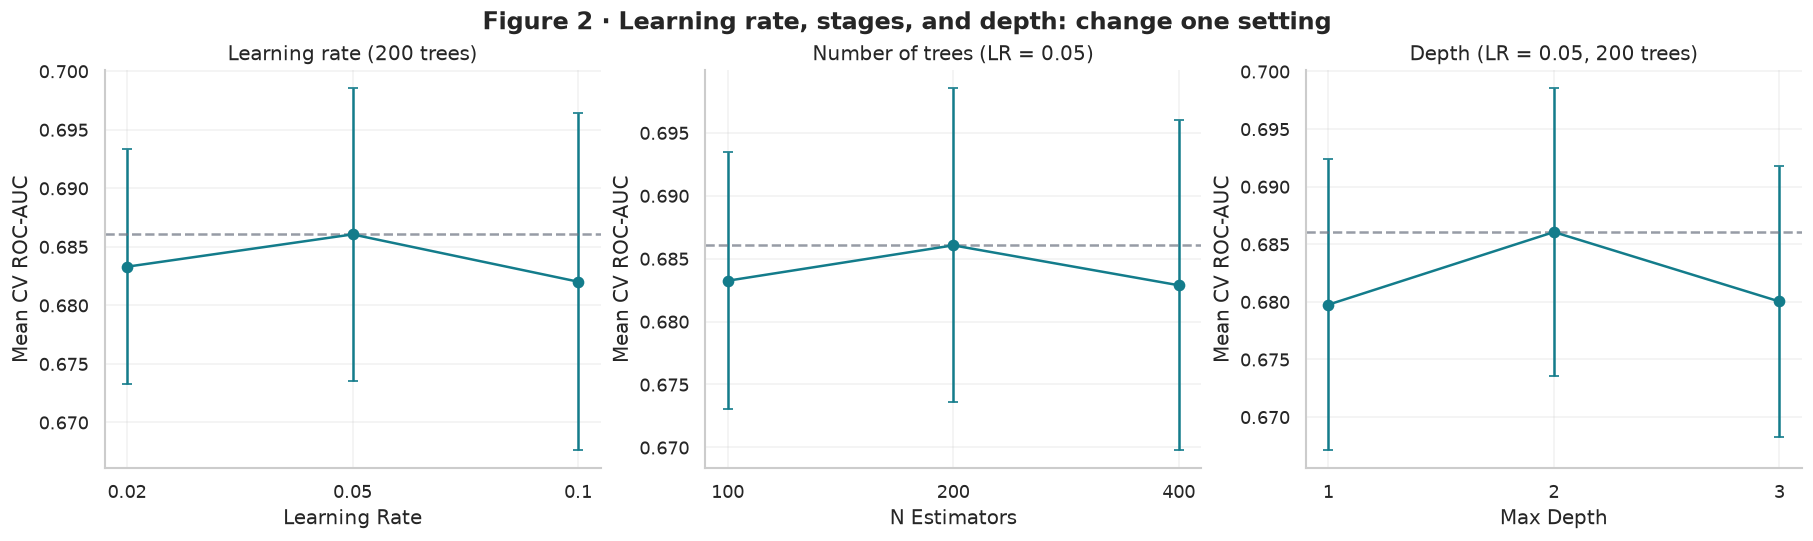

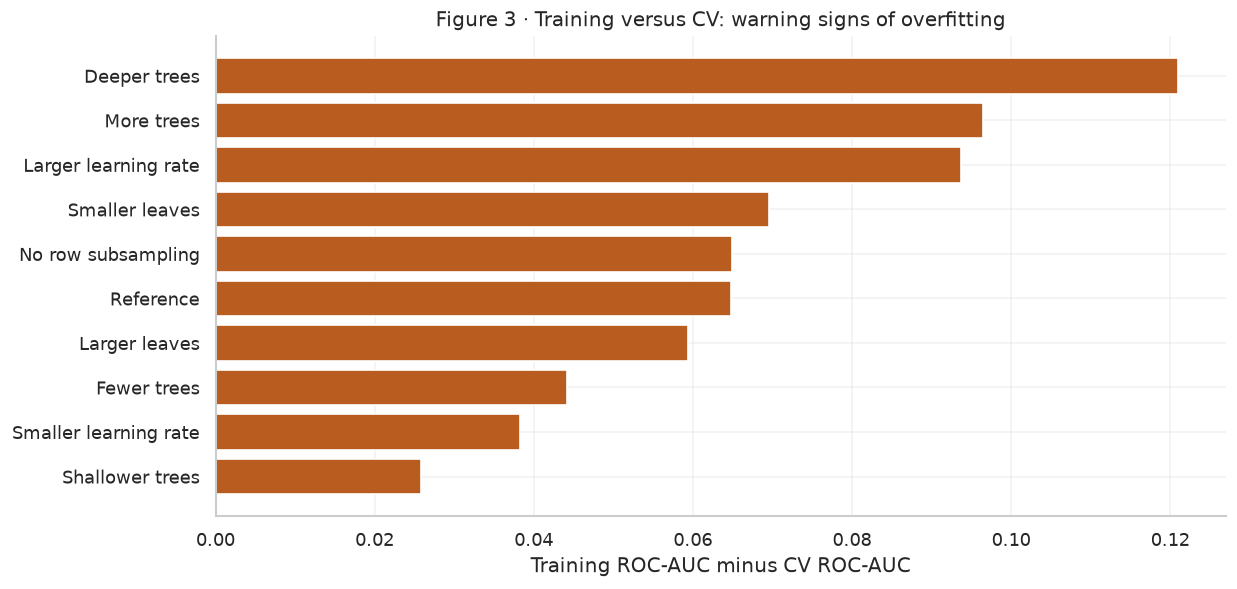

Selected learning_rate: 0.05
Selected n_estimators: 200
Selected max_depth: 2
Selected min_samples_leaf: 50
Selected subsample: 0.8
The CV-selected row is descriptive; the held-out test score has not been examined yet.


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), layout="constrained")
controls = [
    ("learning_rate", "Learning rate (200 trees)", [0.02,0.05,0.10]),
    ("n_estimators", "Number of trees (LR = 0.05)", [100,200,400]),
    ("max_depth", "Depth (LR = 0.05, 200 trees)", [1,2,3]),
]
for ax,(factor,title,order) in zip(axes, controls):
    subset = cv_table.copy()
    for fixed_col,fixed_val in reference.items():
        if fixed_col != factor:
            subset = subset.loc[np.isclose(subset[fixed_col].astype(float), float(fixed_val))]
    subset = subset.set_index(factor).reindex(order).reset_index()
    ax.errorbar(range(len(subset)), subset["CV ROC-AUC"], yerr=subset["CV fold SD"],
                fmt="o-", capsize=3, color=TEAL)
    ax.axhline(cv_table.loc[cv_table.Experiment.eq("Reference"),"CV ROC-AUC"].iloc[0],
               color=GRAY, linestyle="--", alpha=.7)
    ax.set(xticks=range(len(subset)),xticklabels=[str(x) for x in order],
           xlabel=factor.replace('_',' ').title(),ylabel="Mean CV ROC-AUC",title=title)
fig.suptitle("Figure 2 · Learning rate, stages, and depth: change one setting", fontweight="bold")
finish(fig, "figure_2_cv_setting_sweeps")

by_gap = cv_table.sort_values("Train - CV gap",ascending=True)
fig, ax = plt.subplots(figsize=(10.2,4.8),layout="constrained")
ax.barh(by_gap.Experiment, by_gap["Train - CV gap"],color=ORANGE)
ax.set(title="Figure 3 · Training versus CV: warning signs of overfitting",
       xlabel="Training ROC-AUC minus CV ROC-AUC", ylabel="")
finish(fig, "figure_3_generalization_gap")

for field in ["learning_rate","n_estimators","max_depth","min_samples_leaf","subsample"]:
    best = cv_table.loc[cv_table["Rank"].eq(1), field].iloc[0]
    print(f"Selected {field}: {best}")
print("The CV-selected row is descriptive; the held-out test score has not been examined yet.")

## 7. Compare the models on matched training data
The code refits logistic regression and random forest using the same 8,000 training loans and specifications from Week 6. It then compares their CV ROC-AUC, average precision, and training–CV gaps with gradient boosting.

This matters because I want the algorithm to be the main difference, not a change in the dataset. Figure 4 also plots the boosting model's training and validation ROC-AUC as trees are added. If training performance continues to rise while validation performance levels off, later trees may be fitting noise.

I use Figure 4 as a diagnostic only. I do not change the selected tree count after looking at validation performance; that choice was already made through cross-validation.

Comparing Matched logistic on matched training folds...
Comparing Matched random forest on matched training folds...


Model,CV ROC-AUC,CV AP,CV training AUC,Train - CV gap
Gradient boosting,0.6870,0.3588,0.7464,0.0594
Matched logistic,0.6794,0.3512,0.7010,0.0216
Matched random forest,0.6826,0.3552,0.8066,0.1240


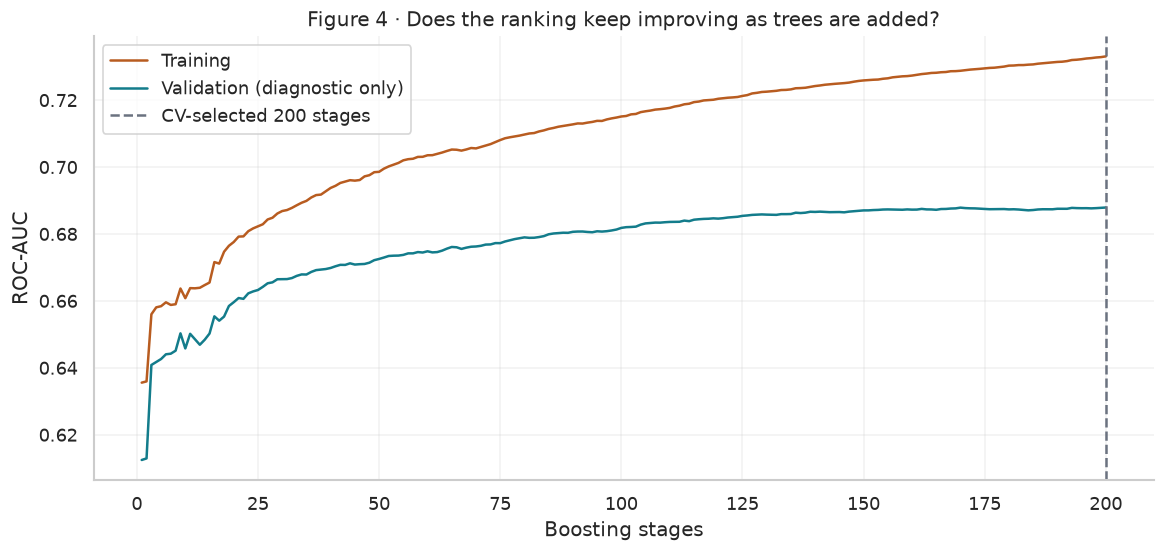

In [22]:
comparison_models = {
    "Gradient boosting": selected_boost,
    "Matched logistic": classifier_pipeline(
        LogisticRegression(C=10, max_iter=5000, solver="lbfgs", random_state=SEED),
        scale_numeric=True),
    "Matched random forest": classifier_pipeline(
        RandomForestClassifier(criterion="entropy", n_estimators=150, max_depth=None,
            min_samples_leaf=20, min_samples_split=100, max_features="sqrt",
            bootstrap=True, n_jobs=N_JOBS, random_state=SEED))
}

comparison_cv = [{"Model":"Gradient boosting", "CV ROC-AUC":boost_search.best_score_,
                  "CV AP":raw_cv.loc[boost_search.best_index_,"mean_test_ap"],
                  "CV training AUC":raw_cv.loc[boost_search.best_index_,"mean_train_auc"]}]
for name in ["Matched logistic", "Matched random forest"]:
    model = comparison_models[name]
    print("Comparing", name, "on matched training folds...", flush=True)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        cv_score = cross_validate(model, X_fit, y_fit, cv=cv_splits,
            scoring={"auc":"roc_auc", "ap":"average_precision"},
            return_train_score=True, n_jobs=N_JOBS, error_score="raise")
        model.fit(X_fit, y_fit)
    if any(issubclass(w.category,ConvergenceWarning) for w in caught):
        raise RuntimeError(f"{name} did not converge; fix training before interpreting results.")
    comparison_cv.append({"Model":name,
        "CV ROC-AUC":cv_score["test_auc"].mean(),
        "CV AP":cv_score["test_ap"].mean(),
        "CV training AUC":cv_score["train_auc"].mean()})

cv_comparison = pd.DataFrame(comparison_cv)
cv_comparison["Train - CV gap"] = cv_comparison["CV training AUC"]-cv_comparison["CV ROC-AUC"]
show_table(cv_comparison,4)
cv_comparison.to_csv(OUTPUT_DIR/"matched_cv_comparison.csv",index=False)

stage_train,stage_val=[],[]
for train_prob, val_prob in zip(
    selected_boost.named_steps["model"].staged_predict_proba(
        selected_boost.named_steps["prepare"].transform(X_fit)),
    selected_boost.named_steps["model"].staged_predict_proba(
        selected_boost.named_steps["prepare"].transform(X_val))):
    stage_train.append(roc_auc_score(y_fit,train_prob[:,1]))
    stage_val.append(roc_auc_score(y_val,val_prob[:,1]))
fig,ax=plt.subplots(figsize=(9.6,4.5),layout="constrained")
ax.plot(range(1,len(stage_train)+1),stage_train,label="Training",color=ORANGE)
ax.plot(range(1,len(stage_val)+1),stage_val,label="Validation (diagnostic only)",color=TEAL)
ax.axvline(len(stage_train),color=GRAY,ls="--",label=f"CV-selected {len(stage_train)} stages")
ax.set(title="Figure 4 · Does the ranking keep improving as trees are added?",
       xlabel="Boosting stages",ylabel="ROC-AUC")
ax.legend()
finish(fig,"figure_4_stagewise_diagnostic")

## 8. Choose the review threshold on validation data
The model outputs probabilities, but a lender still needs a cutoff to decide which loans to flag. This cell tests a fixed range of thresholds on the 10,000 validation loans and selects the one with the highest F1 for each model. It then saves those cutoffs before the test comparison.

I learned in Week 4 that lowering the cutoff can catch many more charge-offs, but it also flags more fully paid borrowers. The table shows precision, recall, F1, and the share of loans flagged so I can see both sides of that decision.

F1 is a consistent way to choose a cutoff for this homework. It is not proof of the financially best lending policy. That would require the cost of additional reviews, missed charge-offs, and the lender's review capacity.

In [23]:
thresholds,validation_rows = {},[]
for name,model in comparison_models.items():
    probs = model.predict_proba(X_val)[:,1]
    chosen,score_table = choose_threshold(y_val,probs,default=.5)
    thresholds[name]=chosen
    validation_rows.append(classification_metrics(name,y_val,probs,chosen,"Validation selected"))
val_results=pd.DataFrame(validation_rows)
show_table(val_results[["Model","Threshold","Precision","Recall","F1","ROC-AUC","Average precision","Flagged share"]],4)
val_results.to_csv(OUTPUT_DIR/"validation_thresholds.csv",index=False)
print("Model settings and thresholds are frozen. The next cell examines the test split for the first time.")

Model,Threshold,Precision,Recall,F1,ROC-AUC,Average precision,Flagged share
Gradient boosting,0.1876,0.2973,0.6724,0.4123,0.6879,0.3451,0.4500
Matched logistic,0.1985,0.3061,0.6307,0.4122,0.6894,0.3406,0.4100
Matched random forest,0.2031,0.3000,0.6332,0.4071,0.6820,0.3384,0.4200


Model settings and thresholds are frozen. The next cell examines the test split for the first time.


## 9. Figures 5 and 6: evaluate the held-out test loans
With the model settings and thresholds fixed, the next cell evaluates all three models on the same 10,000 test loans. It reports ROC-AUC, average precision, precision, recall, F1, and the confusion-matrix counts. It also calculates log loss and Brier score to compare probability errors.

Figure 5 shows the ROC and precision–recall curves. These measure ranking across cutoffs. Figure 6 compares the boosting confusion matrix at the usual 0.50 cutoff and the cutoff selected on validation data. The counts matter more to my project than the colors: how many actual charge-offs were caught, how many were missed, and how many fully paid loans were flagged?

I also look at training, validation, and test scores for signs that the model has not generalized. Log loss and Brier score provide another check, but they do not by themselves prove calibration.

One limitation is that this test partition appeared in earlier weekly notebooks. I did not use it to tune Week 9, but repeated exposure means it is not a completely new independent test of the overall project.

/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)
/usr/local/python/3.14.2/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, U

Model,Rule,Threshold,Precision,Recall,F1,ROC-AUC,Average precision,Flagged share
Gradient boosting,0.50 default,0.5000,0.6143,0.0648,0.1173,0.6971,0.3800,0.0210
Gradient boosting,Validation selected,0.1876,0.2979,0.6683,0.4121,0.6971,0.3800,0.4465
Matched logistic,0.50 default,0.5000,0.5948,0.0804,0.1417,0.6996,0.3769,0.0269
Matched logistic,Validation selected,0.1985,0.3120,0.6503,0.4216,0.6996,0.3769,0.4148
Matched random forest,0.50 default,0.5000,1.0000,0.0010,0.0020,0.6884,0.3586,0.0002
Matched random forest,Validation selected,0.2031,0.2999,0.6286,0.4061,0.6884,0.3586,0.4171


Model,TP,FP,FN,TN,Log loss,Brier
Gradient boosting,1330,3135,660,4875,0.4578,0.1455
Matched logistic,1294,2854,696,5156,0.4605,0.1454
Matched random forest,1251,2920,739,5090,0.4647,0.1480


Model,Split,ROC-AUC,Average precision
Gradient boosting,Training,0.7330,0.4190
Gradient boosting,Validation,0.6879,0.3451
Gradient boosting,Test,0.6971,0.3800
Matched logistic,Training,0.6971,0.3705
Matched logistic,Validation,0.6894,0.3406
Matched logistic,Test,0.6996,0.3769
Matched random forest,Training,0.8065,0.5042
Matched random forest,Validation,0.6820,0.3384
Matched random forest,Test,0.6884,0.3586


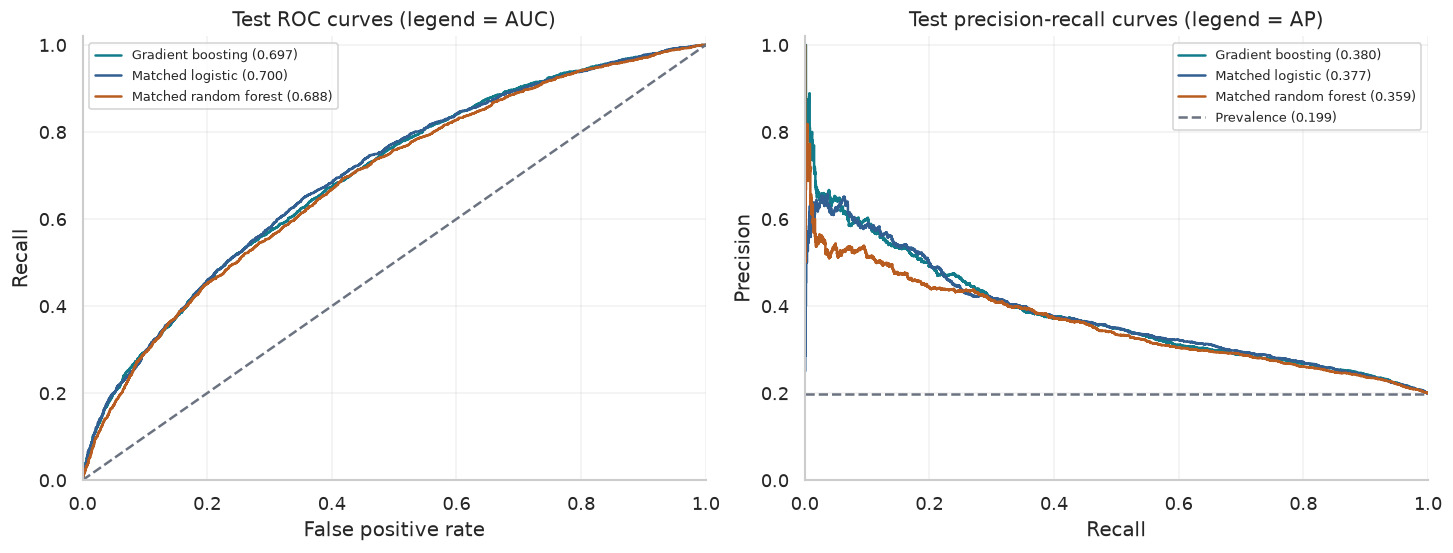

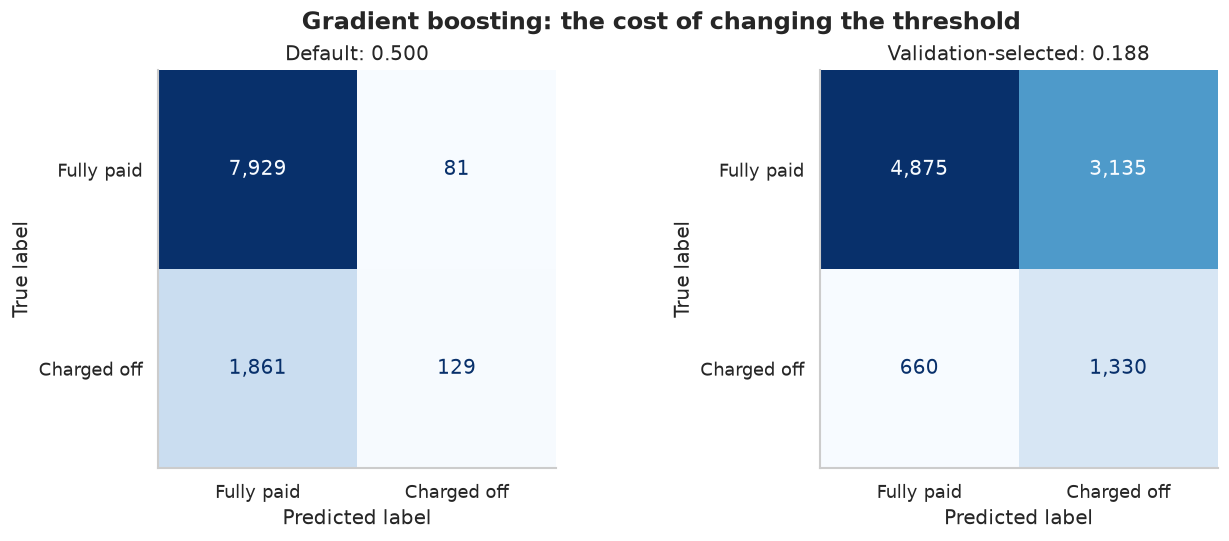

In [25]:
rows,score_dict,generalization=[],{},[]
for name,model in comparison_models.items():
    p_test=model.predict_proba(X_test)[:,1]
    score_dict[name]=p_test
    for rule,threshold in [("0.50 default",.5),("Validation selected",thresholds[name])]:
        result=classification_metrics(name,y_test,p_test,threshold,rule)
        result.update({"Log loss":log_loss(y_test,p_test,labels=[0,1]),
                       "Brier":brier_score_loss(y_test,p_test)})
        rows.append(result)
    for split,frame,target in [("Training",X_fit,y_fit),("Validation",X_val,y_val),("Test",X_test,y_test)]:
        scores=model.predict_proba(frame)[:,1]
        generalization.append({"Model":name,"Split":split,"ROC-AUC":roc_auc_score(target,scores),
                               "Average precision":average_precision_score(target,scores)})

test_results=pd.DataFrame(rows)
gap_results=pd.DataFrame(generalization)
selected_rows=test_results.loc[test_results.Rule.eq("Validation selected")].copy()
show_table(test_results[["Model","Rule","Threshold","Precision","Recall","F1","ROC-AUC","Average precision","Flagged share"]],4)
show_table(selected_rows[["Model","TP","FP","FN","TN","Log loss","Brier"]],4)
show_table(gap_results,4)
test_results.to_csv(OUTPUT_DIR/"test_metrics.csv",index=False)
gap_results.to_csv(OUTPUT_DIR/"generalization_scores.csv",index=False)
pd.DataFrame({"source_row":loans.loc[X_test.index,"source_row"].to_numpy(),
    "observed_charged_off":y_test.to_numpy(),
    "boosted_probability":score_dict["Gradient boosting"],
    "boosted_prediction":(score_dict["Gradient boosting"]>=thresholds["Gradient boosting"]).astype(int)
}).to_csv(OUTPUT_DIR/"boosted_test_predictions.csv",index=False)

plot_ranking(y_test,score_dict,"figure_5_roc_precision_recall")
plot_confusions(y_test,score_dict["Gradient boosting"],.5,thresholds["Gradient boosting"],
                "Gradient boosting","figure_6_boosted_confusion_matrices")

## 10. Figure 7: which features matter most to this model?
This cell uses permutation importance on up to 2,000 validation loans. It shuffles one original predictor at a time, repeats the test three times, and measures the drop in ROC-AUC. Figure 7 shows the ten largest drops, and the notebook saves the full table.

In Week 6, term, FICO, and DTI were important for the random forest. I want to see whether gradient boosting relies on similar information. A larger drop means the fitted model depended more heavily on that feature in this sample. It does not show that changing the feature would cause repayment behavior to change.

The error bars show variation across three repeats, not confidence intervals. Related variables can also share information, which limits how strongly I would interpret an individual feature's rank.

Feature,ROC-AUC drop,Repeat SD
term,0.0629,0.0083
fico_range_low,0.0540,0.0019
loan_amnt,0.0156,0.0061
inq_last_6mths,0.0144,0.0023
dti,0.0132,0.0019
annual_inc,0.0064,0.0032
purpose,0.0048,0.0020
emp_length,0.0026,0.0015
revol_bal,0.0018,0.0022
revol_util,0.0014,0.0008


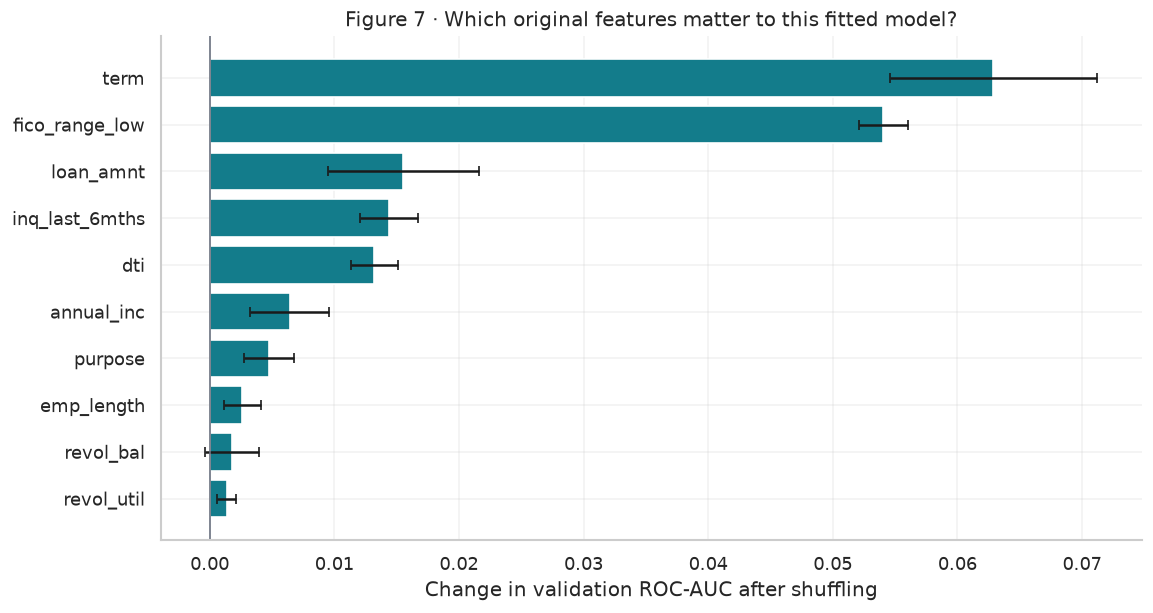

In [26]:
perm_idx = X_val.sample(n=min(2000,len(X_val)),random_state=SEED).index
perm = permutation_importance(selected_boost,X_val.loc[perm_idx],y_val.loc[perm_idx],
    n_repeats=3,scoring="roc_auc",random_state=SEED,n_jobs=N_JOBS)
importance=pd.DataFrame({"Feature":FEATURES,"ROC-AUC drop":perm.importances_mean,
                         "Repeat SD":perm.importances_std}).sort_values("ROC-AUC drop",ascending=False)
show_table(importance.head(10),4)
importance.to_csv(OUTPUT_DIR/"validation_permutation_importance.csv",index=False)
top=importance.head(10).iloc[::-1]
fig,ax=plt.subplots(figsize=(9.5,5),layout="constrained")
ax.barh(top.Feature,top["ROC-AUC drop"],xerr=top["Repeat SD"],color=TEAL,capsize=3)
ax.axvline(0,color=GRAY,lw=1)
ax.set(title="Figure 7 · Which original features matter to this fitted model?",
       xlabel="Change in validation ROC-AUC after shuffling",ylabel="")
finish(fig,"figure_7_boosted_feature_importance")

## 11. What these results mean for my capstone
The tables and figures above give me enough information to compare the selected boosting model with the two Week 6 baselines. Below, I summarize the actual saved results: the CV-selected settings, training–CV gap, test ranking scores, and the number of charged-off versus fully paid loans flagged.

My question is not simply which model has the highest ROC-AUC. I also want to know whether any improvement catches enough additional charge-offs to justify more false positives. I am treating differences of a few thousandths cautiously, particularly when the CV folds vary more than that.

The discussion below is written from the executed notebook output. If I rerun the analysis with a different file or sample, I would need to check and update these numbers rather than assuming they will stay the same.


### What I learned from these results
I wanted to know whether gradient boosting would rank charge-off risk better than the models I had already tested, without creating a much larger review burden. The results were mixed.

Model selection. Cross-validation selected 200 trees, a 0.05 learning rate, depth 2, 50 samples per leaf, and 0.80 subsampling. Its mean training ROC-AUC was 0.746, compared with 0.687 across the three CV folds. The 0.059 gap suggests that the model fits the training loans more easily than unseen folds. It does not prove how much performance would drop on future borrowers, but it gives me a reason to watch overfitting.

Test comparison. On the same 10,000 test loans, boosting reached ROC-AUC 0.697 and average precision 0.380. The matched logistic regression reached 0.700 ROC-AUC and 0.377 AP, while random forest reached 0.688 ROC-AUC and 0.359 AP. Boosting slightly improved average precision over logistic regression but did not improve its ROC-AUC. These differences are small. The winning model may change with another sample, so I would not describe boosting as clearly better.

| Model | Test ROC-AUC | Average precision |
|---|---:|---:|
| Logistic regression | 0.700 | 0.377 |
| Gradient boosting | 0.697 | 0.380 |
| Random forest | 0.688 | 0.359 |

The threshold changed the practical result. With its validation-selected cutoff of 0.188, boosting detected 1,330 of the 1,990 charged-off loans and missed 660. It also incorrectly flagged 3,135 fully paid loans. Recall was 66.8%, but precision was only 29.8%. In other words, most of the loans sent for review would actually have been fully paid.

| Boosting result at selected cutoff | Count or rate |
|---|---:|
| Charge-offs detected (TP) | 1,330 |
| Charge-offs missed (FN) | 660 |
| Fully paid loans flagged (FP) | 3,135 |
| Fully paid loans not flagged (TN) | 4,875 |
| Recall | 66.8% |
| Precision | 29.8% |

Compared with logistic regression on these same loans, boosting caught 36 more charge-offs, but it also flagged 281 more fully paid loans. That is the result I would pay the most attention to. Whether those extra detections are worth the additional reviews depends on the cost of a missed charge-off and the cost of reviewing someone who would repay. ROC-AUC alone cannot answer that.

What tuning showed me. The reference configuration reached 0.686 CV ROC-AUC. Changing one setting at a time produced the following results:

| Change from reference | CV ROC-AUC | Difference |
|---|---:|---:|
| Smaller learning rate | 0.683 | -0.003 |
| Larger learning rate | 0.682 | -0.004 |
| Fewer trees | 0.683 | -0.003 |
| More trees | 0.683 | -0.003 |
| Shallower trees | 0.680 | -0.006 |
| Deeper trees | 0.680 | -0.006 |
| Smaller leaf size | 0.684 | -0.002 |
| Larger leaf size | 0.687 | +0.001 |
| No row subsampling | 0.684 | -0.002 |

The larger minimum leaf size performed slightly better and had a smaller training–CV gap than the reference. That is consistent with regularization helping, but a 0.001 gain is not strong evidence by itself. The selected configuration's CV fold standard deviation was about 0.012, larger than most differences among the experiments. Increasing tree depth or adding more trees did not help at the settings I tested. I also cannot conclude that 0.05 is the best learning rate at every tree count, because those controls were not searched together.

Did the model generalize? Its test ROC-AUC of 0.697 was about 0.010 above its CV mean of 0.687. I would not treat that as proof that it generalizes especially well. I am more interested in the overall pattern: a noticeable training–CV gap, small test-score differences among models, and the trade-off between additional charge-offs detected and additional false positives.

Feature importance. Permutation importance ranked term and fico_range_low highest for boosting, with validation ROC-AUC drops of approximately 0.063 and 0.054. That tells me the fitted model relies on these inputs to rank loans. It does not establish that changing the loan term or FICO score would cause a different repayment outcome.

My takeaway. Gradient boosting was competitive, but more model complexity did not produce a clear improvement over logistic regression. I would keep checking both ranking metrics and threshold errors, then test on later-issued loans before deciding which model is more useful in practice. For loan analysts, which loans get flagged matters at least as much as a small difference in ROC-AUC.


## 12. Limits and next steps
My Week 6 results showed that a more flexible model can fit the training data well and still struggle with new loans. Gradient boosting gave me more ways to control complexity, but it did not clearly beat logistic regression in this test. For my capstone, I would keep the simpler model as a serious baseline rather than assume boosting is better because it uses more trees.

There are several limits I would carry into Milestone Two:
- Limited tuning: I tested ten configurations, changing one setting at a time. A broader learning-rate and tree-count search could produce a different result.
- Matched training sample: The 8,000-loan subset makes Weeks 5, 6, and 9 comparable, but it does not tell me how boosting would perform using the full 30,000 training loans.
- Repeated test use: I reused the previous test split. A later-period holdout would be stronger evidence that these results generalize.
- Dataset coverage: Resolved, accepted Lending Club loans do not represent rejected applicants or loans still in progress. Repeated borrowers and time changes may also matter.
- Decision costs: The validation-F1 cutoff is not a lending policy. I would still need to examine probability calibration, borrower-group performance, review costs, and the consequences of incorrectly flagging borrowers.
For Milestone Two, I can use the CV tuning comparison, overfitting plot, test ROC/PR curves, and confusion matrices as evidence. The final report asks for 3–8 legible figures or tables across the relevant weeks, so I would select the clearest ones instead of including every graph.
Sources
- Wordsforthewise. (n.d.). Lending Club [Data set]. Kaggle. https://www.kaggle.com/datasets/wordsforthewise/lending-club
- Scikit-learn developers. (n.d.). Ensembles: Gradient boosting, random forests, bagging, voting, stacking. https://scikit-learn.org/stable/modules/ensemble.html